# Exploratory Data Analysis (EDA)
In this notebook, we analyze the telecom customer churn dataset to uncover patterns and relationships.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Load Data
We load the cleaned dataset produced in the `01_data_cleaning` step.

In [2]:
# Load the cleaned dataset
df = pd.read_csv('../data/processed/churn_clean.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag
0,7590-VHVEG,Female,No,Yes,No,1,No,No,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,No,No,No,45,No,No,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


## 2. Overall Churn Distribution

C:\Users\eFuture\AppData\Local\Temp\ipykernel_2040\2782391980.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Churn', palette='Set2')


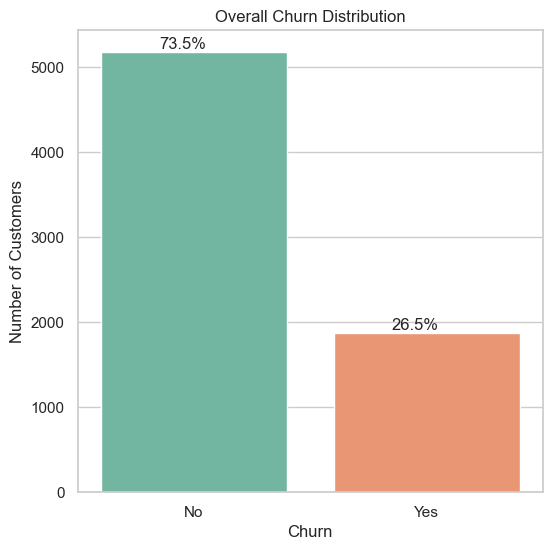

In [3]:
# Overall churn rate
plt.figure(figsize=(6, 6))
ax = sns.countplot(data=df, x='Churn', palette='Set2')
plt.title('Overall Churn Distribution')
plt.ylabel('Number of Customers')

# Calculate percentages
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2 - 0.05
    y = p.get_y() + p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom')
    
plt.show()

## 3. Churn by Categorical Features (Contract, Internet Service, Payment Method)

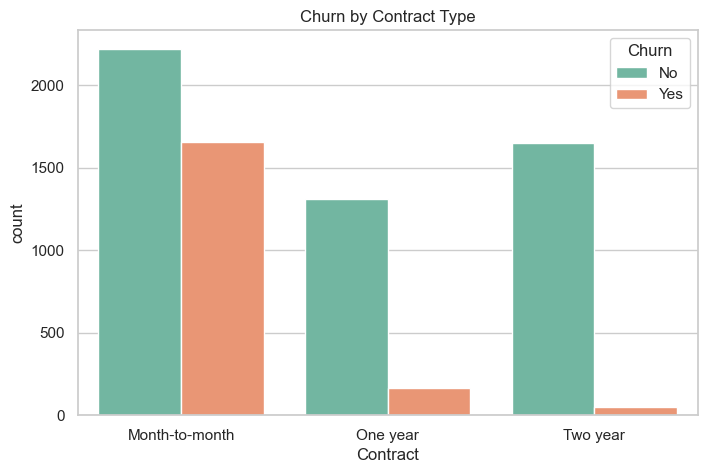

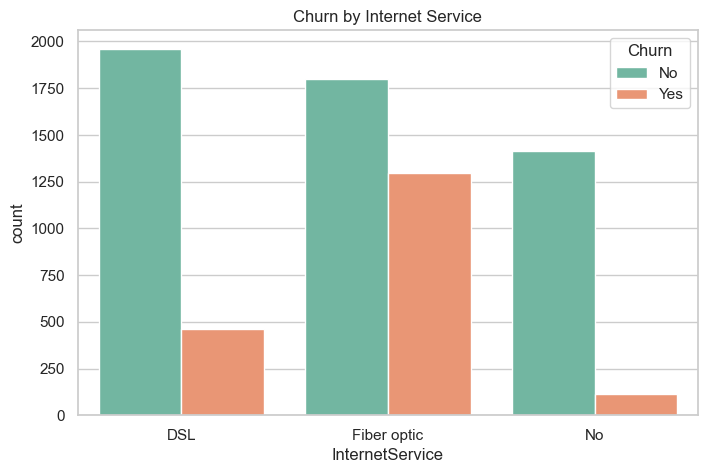

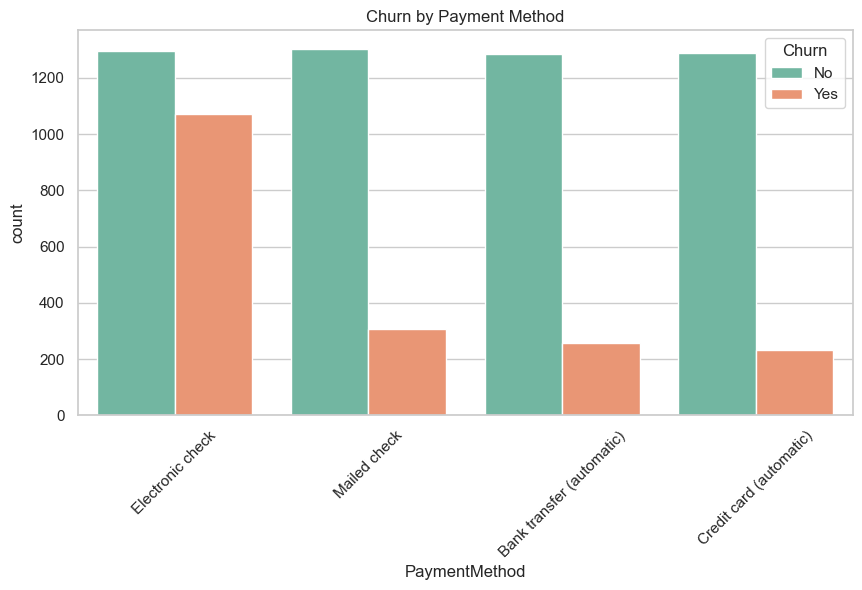

In [4]:
# Churn by Contract
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set2')
plt.title('Churn by Contract Type')
plt.show()

# Churn by Internet Service
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='InternetService', hue='Churn', palette='Set2')
plt.title('Churn by Internet Service')
plt.show()

# Churn by Payment Method
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='PaymentMethod', hue='Churn', palette='Set2')
plt.title('Churn by Payment Method')
plt.xticks(rotation=45)
plt.show()

## 4. Churn by Numerical Features (Tenure, Monthly Charges)

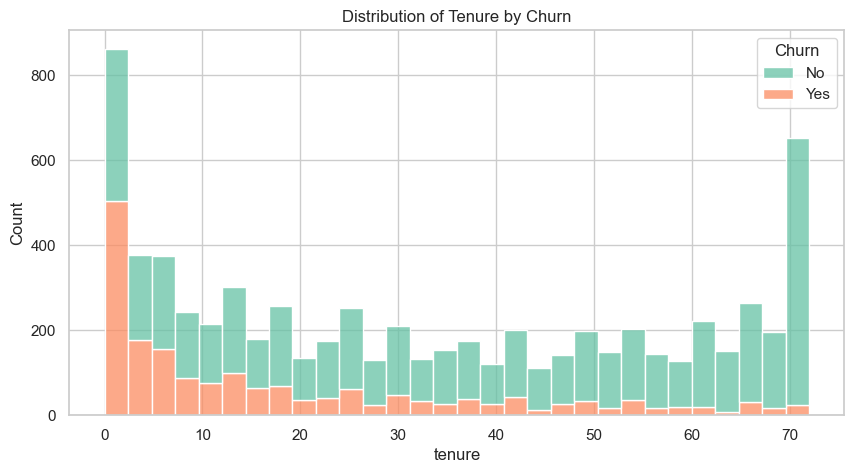

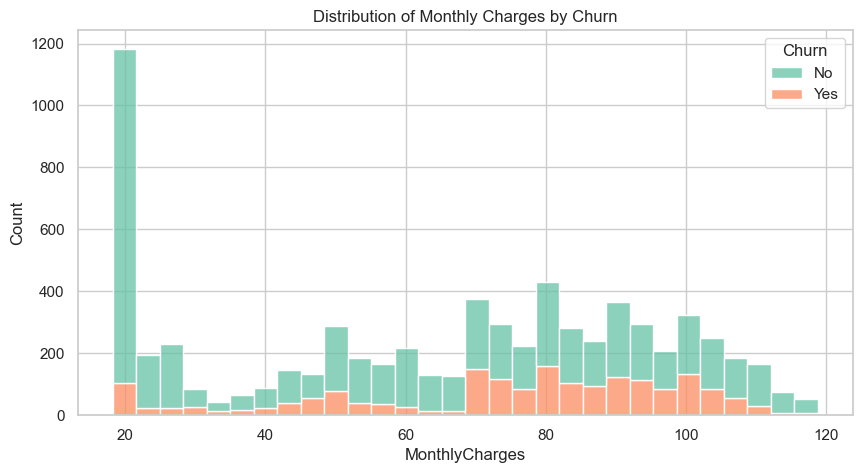

In [5]:
# Distribution of Tenure
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='tenure', hue='Churn', multiple="stack", bins=30, palette='Set2')
plt.title('Distribution of Tenure by Churn')
plt.show()

# Distribution of Monthly Charges
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', multiple="stack", bins=30, palette='Set2')
plt.title('Distribution of Monthly Charges by Churn')
plt.show()

## 5. Correlation Analysis

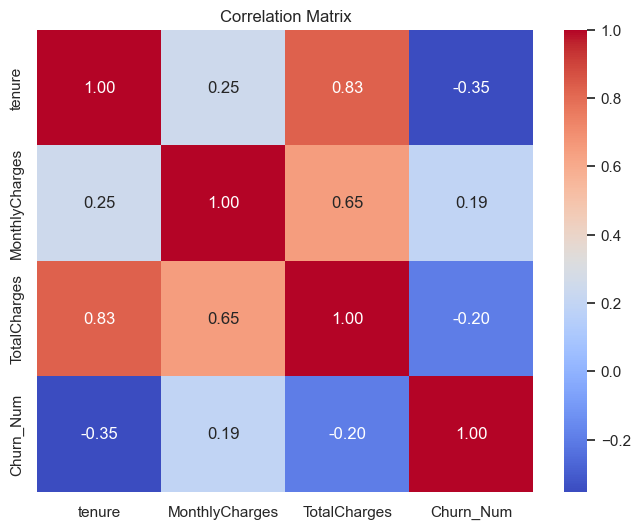

In [6]:
# Select numeric features for correlation
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
if 'Churn' in df.columns:
    # Temporarily encode Churn as numeric for correlation
    df['Churn_Num'] = df['Churn'].map({'Yes': 1, 'No': 0})
    numeric_cols.append('Churn_Num')

plt.figure(figsize=(8, 6))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

if 'Churn_Num' in df.columns:
    df.drop('Churn_Num', axis=1, inplace=True)